In [1]:
# THIS SCRIPT IS MEANT to run side-by-side with the analyse_ngs.ipynb notebook, 
# as a rough exploration of the NGS results and DICOM metadata, to identify any potential issues with the data or the analysis
import pandas as pd
from pathlib import Path
import platform
import importlib
import utils
importlib.reload(utils)
from utils import open_in_itksnap, load_json_dicom_merged, truncate_right, drop_common_columns

In [2]:
if platform.system() == 'Windows':
    netapp_dir = Path(r"W:/MinMo_CI/")
else:
    netapp_dir = Path.home() / "Documents/Postdoc_epilepsy/MinMo_CI"

In [3]:
json_dicom_df = utils.load_json_dicom_merged(netapp_dir, merge_on=['SubjectID', 'SeriesNumber', 'PulseSequenceName'], how='left')
# load the NGS results csv file to get the NGS results for each subject
ngs_results_df = pd.read_csv(netapp_dir / "derivatives" / f"NGS_results_all.csv")
# load the group key csv file to get the group labels (minmo or not) and age for each subject
group_key_df = pd.read_csv(netapp_dir / "derivatives" / "group_key.csv")
# load the DICOM inventory csv file to get the DICOM metadata of all scans INCLUDING LOCALISER scans for each subject
dicom_df = pd.read_csv(netapp_dir / "derivatives" / "DICOM_inventory_all.csv")

JSON: 743 rows, DICOM: 1234 rows, Merged: 743 rows


In [4]:
# clean the SubjectID column in the dataframes to match the format across all dataframes (replace 'MinMo-' with 'Min-Mo-' and strip whitespace)
json_dicom_df['SubjectID'] = json_dicom_df['SubjectID'].str.replace('Min-Mo-', 'MinMo-').str.strip()
group_key_df['SubjectID'] = group_key_df['SubjectID'].str.replace('Min-Mo-', 'MinMo-').str.strip()
ngs_results_df['SubjectID'] = ngs_results_df['SubjectID'].str.replace('Min-Mo-', 'MinMo-').str.strip()
dicom_df['SubjectID'] = dicom_df['SubjectID'].str.replace('Min-Mo-', 'MinMo-').str.strip()

In [5]:
# create a merge key for both dataframes based on the file path of the nifti file in the derivatives folder, which is unique for each series
json_dicom_df['MergeKey'] = json_dicom_df['NIfTIPath'].apply(lambda x: str(Path(x)))
ngs_results_df['MergeKey'] = ngs_results_df['FilePath'].apply(lambda x: str(Path(x)))
json_dicom_df = drop_common_columns(json_dicom_df, ngs_results_df, keep_cols=['MergeKey', 'NifTIPath', 'SeriesNumber', 'PulseSequenceName'])
# merge on MergeKey which is the file path of the nifti file in the derivatives folder, which is unique for each series
merged_df = ngs_results_df.merge(json_dicom_df, on='MergeKey', how='inner')
# merge the merged dataframe with the group key dataframe to get the group labels for each subject
merged_df = merged_df.merge(group_key_df, on='SubjectID', how='left')

In [ ]:
# convert the FrameAcquisitionDateTime column in the dicom_df dataframe to a datetime object, and store it in a new column called AcqDateTime
dicom_df['AcqDateTime'] = pd.to_datetime(dicom_df['FrameAcquisitionDateTime'].astype(str).str.split('.').str[0], format='%Y%m%d%H%M%S', errors='coerce')
# calculate session start timestamp for each subjectID
session_start = dicom_df.loc[dicom_df.groupby('SubjectID')['AcqDateTime'].idxmin(), ['SubjectID', 'AcqDateTime']].rename(columns={'AcqDateTime': 'SessionStart'})

dicom_df = dicom_df.merge(session_start, on='SubjectID', how='left')
dicom_df['TimeSinceSessionStart'] = (dicom_df['AcqDateTime'] - dicom_df['SessionStart']).dt.total_seconds() / 60  # in minutes


count    939.000000
mean      14.736670
std       12.171575
min        0.000000
25%        5.433333
50%       13.150000
75%       21.575000
max      105.816667
Name: TimeSinceSessionStart, dtype: float64
NaT count: 295


In [9]:
# add QC flags and other useful columns to the merged dataframe
merged_df['QC_flag_1'] = merged_df['Num_voxels_in_mask_Eroded'] < 1000  # flag if fewer than 1000 brain voxels after erosion
merged_df['QC_flag_2'] = merged_df['Num_voxels_in_mask_Eroded'] / merged_df['Num_voxels_in_mask'] < 0.5  # flag if fewer than 50% of brain voxels remain after erosion  
# sequence-agnostic filters
print(f"Total rows: {len(merged_df)}")
print(merged_df['PulseSequenceName'].value_counts())
clean_df = merged_df[
    (~merged_df['ImageType'].str.contains('DERIVED', na=False)) & # MPR excluded in this filter
    (~merged_df['ImageType'].str.contains('MINIMUM', na=False)) & # MIP excluded in this filter
    (~merged_df['ImageType'].str.contains('T2_STAR', na=False)) & # SWI T2* excluded in this filter
    (~merged_df['FilePath'].str.contains('_ph.nii', na=False)) & # SWI phase excluded in this filter
    (~merged_df['FilePath'].str.contains('Med_DRS', na=False)) & # Med_DRS seen in T2SE files at 3T excluded in this filter
    (~merged_df['ProtocolName'].str.contains('t1post', case=False, na=False)) &# T1 post contrast excluded in this filter
    (~merged_df['QC_flag_1']) & # fewer than 1000 brain voxels after erosion
    (~merged_df['QC_flag_2']) # fewer than 50% of brain voxels remain after erosion
].copy()
print(f"After sequence agnostic filters: {len(clean_df)}")
print(clean_df['PulseSequenceName'].value_counts())

Total rows: 722
PulseSequenceName
*spcR_42ns      193
*swi3d1r        187
*tse2d1_17      177
*spcR_40ns       66
*spcir_220ns     51
*spcir_210ns     43
*spcR_50ns        5
Name: count, dtype: int64
After sequence agnostic filters: 271
PulseSequenceName
*tse2d1_17      126
*swi3d1r         52
*spcR_42ns       33
*spcir_220ns     30
*spcir_210ns     15
*spcR_40ns       14
*spcR_50ns        1
Name: count, dtype: int64


In [10]:
clean_df = clean_df.merge(
    dicom_df[['SubjectID', 'SeriesNumber', 'PulseSequenceName', 'TimeSinceSessionStart']],
    on=['SubjectID', 'SeriesNumber', 'PulseSequenceName'],
    how='left'
)

In [13]:
print(clean_df['TimeSinceSessionStart'].describe())
print(clean_df.groupby('MinMo_Group')['TimeSinceSessionStart'].describe())

count    271.000000
mean      14.431550
std       11.310481
min        0.916667
25%        4.883333
50%       12.866667
75%       20.825000
max       53.250000
Name: TimeSinceSessionStart, dtype: float64
               count       mean        std       min       25%    50%  \
MinMo_Group                                                             
With MinMo     104.0  13.663462  10.343942  0.916667  3.945833  13.35   
Without MinMo  167.0  14.909880  11.877897  1.100000  6.616667  12.80   

                     75%        max  
MinMo_Group                          
With MinMo     20.308333  41.566667  
Without MinMo  21.208333  53.250000  


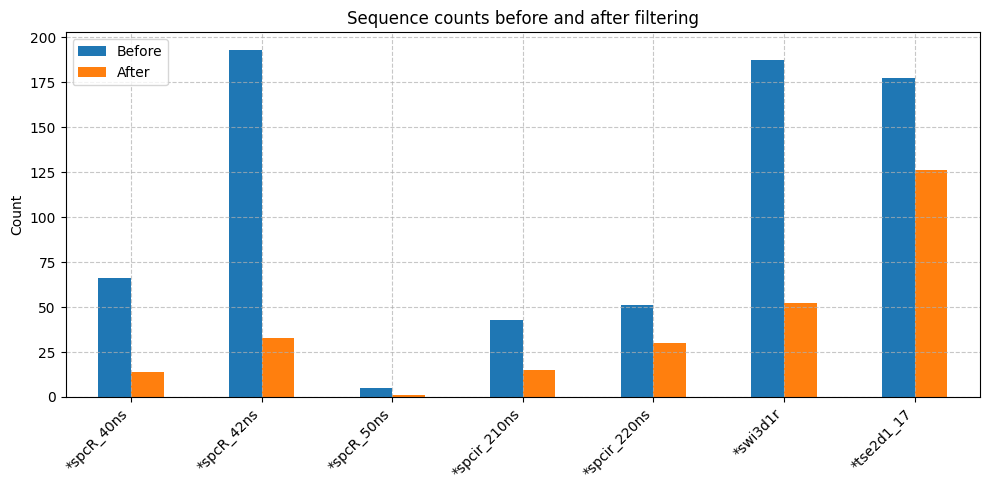

In [14]:
import matplotlib.pyplot as plt
before = merged_df['PulseSequenceName'].value_counts()
after = clean_df['PulseSequenceName'].value_counts()

plot_df = pd.DataFrame({'Before': before, 'After': after}).fillna(0)

plot_df.plot(kind='bar', figsize=(10, 5))
plt.title('Sequence counts before and after filtering')
plt.xlabel('')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Count')
plt.tight_layout()
# turn on grid
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.grid(axis='x', linestyle='--', alpha=0.7)

In [ ]:
'''cols_to_profile = ['SubjectID', 'PulseSequenceName', 'Orientation', 'MagneticFieldStrength', 
                   'MRAcquisitionType', 'SliceThickness', 'EchoTime', 'RepetitionTime',
                   'IsSWI','Isspcir', 'IsspcR', 'IsPhase', 'IsMIP', 'Is3D','Mean_NGS_Eroded',
                   'Q25_NGS_Eroded', 'Q75_NGS_Eroded',
                   'Median_NGS_Eroded', 'Std_NGS_Eroded', 'N_slices', 
                   'Num_voxels_in_mask_Eroded', 'QC_flag', 'QC_flag_2', 
                   'isAnat', 'isDerived', 'isFunc', 'MinMo_Group', 'Age at scan']
profile = ProfileReport(merged_df[cols_to_profile], title="NGS Results Profiling Report", explorative=True)
profile.to_file(netapp_dir / "derivatives" / f"NGS_results_profiling_report{suffix}.html")'''

In [15]:
clean_df['Z_score'] = clean_df.groupby(['PulseSequenceName', 'Orientation'])['Median_NGS_Eroded'].transform(lambda x: (x - x.mean())/x.std())
lmm_df = clean_df[clean_df['PulseSequenceName'] != '*spcR_50ns'].dropna(subset=['Z_score', 'MinMo_Group', 'SubjectID', 'TimeSinceSessionStart'])


IsRPT
False    258
True      13
Name: count, dtype: int64


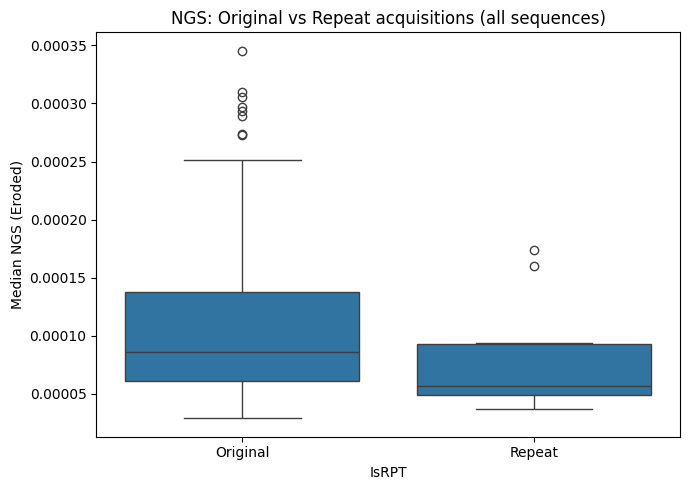

In [26]:
import seaborn as sns
clean_df['IsRPT'] = clean_df['ProtocolName'].str.contains('RPT|repeat|rpt', case=False, na=False)

silent_repeats = {
    'MinMo-031': [4],    # second ax_t2_tse, silent repeat
    'MinMo-033': [13],   # second t1_space_sag, silent repeat
    'MinMo-063': [5],    # clean repeat of motion corrupted Series 3
}

for subject, series_nums in silent_repeats.items():
    mask = (clean_df['SubjectID'] == subject) & (clean_df['SeriesNumber'].isin(series_nums))
    clean_df.loc[mask, 'IsRPT'] = True

print(clean_df['IsRPT'].value_counts())

plt.figure(figsize=(7, 5))
sns.boxplot(x='IsRPT', y='Median_NGS_Eroded', data=clean_df)
plt.xticks([0, 1], ['Original', 'Repeat'])
plt.title('NGS: Original vs Repeat acquisitions (all sequences)')
plt.ylabel('Median NGS (Eroded)')
plt.tight_layout()

In [24]:
import statsmodels.formula.api as smf
model = smf.mixedlm(
    'Z_score ~ C(MinMo_Group) + Q("Age at scan") + SliceThickness ',
    data=lmm_df,
    groups=lmm_df['SubjectID']
).fit()
print(model.summary())

                  Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       Z_score  
No. Observations:        270           Method:                   REML     
No. Groups:              68            Scale:                    0.7055   
Min. group size:         1             Log-Likelihood:           -371.8877
Max. group size:         7             Converged:                Yes      
Mean group size:         4.0                                              
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                        0.481    0.363  1.324 0.185 -0.231  1.193
C(MinMo_Group)[T.Without MinMo]  0.055    0.172  0.321 0.748 -0.282  0.392
Q("Age at scan")                -0.048    0.027 -1.790 0.074 -0.100  0.005
SliceThickness                   0.020    0.

In [22]:
lmm_df_no_rpt = lmm_df[~lmm_df['ProtocolName'].str.contains('RPT|repeat|rpt', case=False, na=False)]
print(f"Before: {len(lmm_df)}, After: {len(lmm_df_no_rpt)}")

model_no_rpt = smf.mixedlm(
    'Z_score ~ C(MinMo_Group) + Q("Age at scan")',
    data=lmm_df_no_rpt,
    groups=lmm_df_no_rpt['SubjectID']
).fit()
print(model_no_rpt.summary())


Before: 270, After: 260
                  Mixed Linear Model Regression Results
Model:                   MixedLM       Dependent Variable:       Z_score  
No. Observations:        260           Method:                   REML     
No. Groups:              68            Scale:                    0.7095   
Min. group size:         1             Log-Likelihood:           -358.0947
Max. group size:         6             Converged:                Yes      
Mean group size:         3.8                                              
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                        0.551    0.359  1.535 0.125 -0.153  1.255
C(MinMo_Group)[T.Without MinMo]  0.052    0.175  0.297 0.766 -0.291  0.395
Q("Age at scan")                -0.049    0.027 -1.785 0.074 -0.102  0.005
Group Var           